# Final Project 2, Part 3: Principal Component Analysis
**DO YOU EVEN LOAF? Does Seoul Bulk or Cut?** | CDS 303

This notebook applies PCA to the variables prepared in
[01_data_integration.ipynb](01_data_integration.ipynb). Each row is one 행정동 in 2025 (365 행정동).
It follows the steps from Demo 6 and the Week 11 lecture:

1. Standardize the data (done in notebook 01)
2. Compute eigenvalues and eigenvectors
3. Select the top *r* components
4. Project the data onto the retained components

## 0. Setup

In [1]:
from pathlib import Path

# data pre-processing
import numpy as np
import pandas as pd

# data mining
from sklearn.decomposition import PCA

# visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducible settings
RANDOM_STATE = 2000
np.random.seed(RANDOM_STATE)

PROCESSED = Path("../data/processed")
FIGURES = Path("../figures")
FIGURES.mkdir(parents=True, exist_ok=True)

KEY = "Administrative_Dong_Code"

# Plot style: one hue for the data, gray for reference lines, light grid
DATA_COLOR = "#2a78d6"
REF_COLOR = "#8a8984"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})

## 1. Input variables and preprocessing

We load the standardized matrix created in notebook 01, plus the unstandardized table for reference.

In [2]:
X_std = pd.read_csv(PROCESSED / "dong_pca_input_standardized.csv").set_index(KEY)
features = pd.read_csv(PROCESSED / "dong_features_2025.csv").set_index(KEY)

PCA_VARS = X_std.columns.tolist()
print("Rows (행정동):", X_std.shape[0])
print("PCA input variables:", X_std.shape[1])

Rows (행정동): 365
PCA input variables: 8


### 1.1 Variables used

In [3]:
variable_info = pd.DataFrame({
    "variable": PCA_VARS,
    "what it measures": [
        "Share of the 행정동's transactions that go to bakeries",
        "Share of the 행정동's transactions that go to gyms",
        "Share of gym transactions between 06:00 and 11:00",
        "Share of gym transactions between 17:00 and 24:00",
        "Share of bakery customers in their 20s and 30s",
        "Share of gym customers who are female",
        "Bakeries as a share of all stores",
        "Licensed gyms per 1,000 stores",
    ],
    "group": ["Activity", "Activity", "Timing", "Timing", "Customers", "Customers", "Supply", "Supply"],
    "transformation": ["square root", "natural log", "none", "none", "none", "none", "square root", "none"],
})
variable_info

,variable,what it measures,group,transformation
0,bakery_txn_share,Share of the 행정동's transactions that go to bak...,Activity,square root
1,gym_txn_share,Share of the 행정동's transactions that go to gyms,Activity,natural log
2,gym_morning_share,Share of gym transactions between 06:00 and 11:00,Timing,none
3,gym_evening_share,Share of gym transactions between 17:00 and 24:00,Timing,none
4,bakery_young_share,Share of bakery customers in their 20s and 30s,Customers,none
5,gym_female_share,Share of gym customers who are female,Customers,none
6,bakery_store_share,Bakeries as a share of all stores,Supply,square root
7,gym_density,"Licensed gyms per 1,000 stores",Supply,none


### 1.2 How missing values and measurement scale were handled

- **Missing values:** 60 of 425 행정동 had no bakery or no gym transactions in 2025, so their shares could not be calculated.
  We dropped them instead of imputing (see notebook 01). The PCA input has no missing values.
- **Skewness:** bakery_txn_share and bakery_store_share were square-root transformed, and gym_txn_share was log transformed.
- **Scale:** all variables were standardized to mean 0 and standard deviation 1, because PCA is not scale invariant.

We check these below.

In [4]:
checks = pd.DataFrame({
    "missing values": X_std.isna().sum(),
    "mean": X_std.mean().round(3),
    "std": X_std.std(ddof=0).round(3),
})
checks

,missing values,mean,std
bakery_txn_share,0,-0.0,1.0
gym_txn_share,0,0.0,1.0
gym_morning_share,0,0.0,1.0
gym_evening_share,0,-0.0,1.0
bakery_young_share,0,0.0,1.0
gym_female_share,0,0.0,1.0
bakery_store_share,0,0.0,1.0
gym_density,0,0.0,1.0


## 2. Component selection

### 2.1 Fit PCA and compute eigenvalues

We fit PCA with all 8 components first, so we can see how much variance each one explains before deciding how many to keep.
For standardized data, each original variable has variance 1, so the total variance is 8 and the **average eigenvalue is 1**.

In [5]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_std)

n_components = len(PCA_VARS)
pc_names = [f"PC{i}" for i in range(1, n_components + 1)]

variance_table = pd.DataFrame({
    "eigenvalue": pca_full.explained_variance_,
    "explained variance ratio": pca_full.explained_variance_ratio_,
    "cumulative ratio": np.cumsum(pca_full.explained_variance_ratio_),
}, index=pc_names)

print("Total variance:", round(pca_full.explained_variance_.sum(), 3))
print("Average eigenvalue:", round(pca_full.explained_variance_.mean(), 3))
variance_table.style.format({"eigenvalue": "{:.3f}",
                             "explained variance ratio": "{:.1%}",
                             "cumulative ratio": "{:.1%}"})

Total variance: 8.022
Average eigenvalue: 1.003


,eigenvalue,explained variance ratio,cumulative ratio
PC1,1.904,23.7%,23.7%
PC2,1.345,16.8%,40.5%
PC3,1.180,14.7%,55.2%
PC4,1.045,13.0%,68.2%
PC5,0.841,10.5%,78.7%
PC6,0.631,7.9%,86.6%
PC7,0.556,6.9%,93.5%
PC8,0.519,6.5%,100.0%


### 2.2 Scree plot

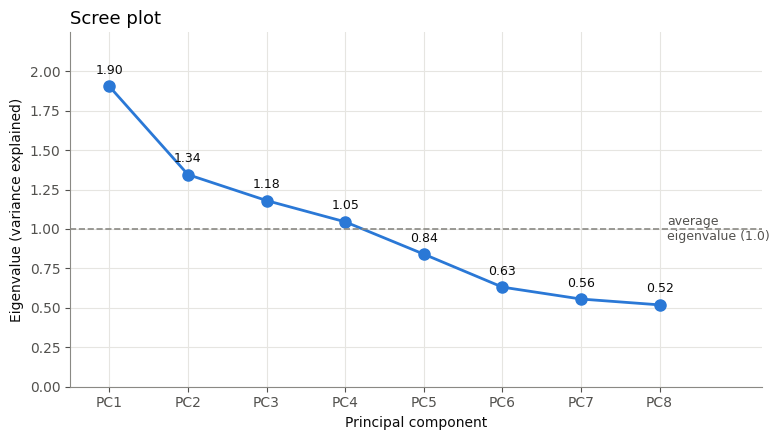

In [6]:
x = np.arange(1, n_components + 1)
avg_eigenvalue = pca_full.explained_variance_.mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, pca_full.explained_variance_, marker="o", markersize=8, linewidth=2, color=DATA_COLOR)
ax.axhline(avg_eigenvalue, linestyle="--", linewidth=1.2, color=REF_COLOR)
ax.text(n_components + 0.1, avg_eigenvalue, "average\neigenvalue (1.0)", va="center", fontsize=9, color="#52514e")
for xi, ev in zip(x, pca_full.explained_variance_):
    ax.annotate(f"{ev:.2f}", (xi, ev), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=9, color="#0b0b0b")
ax.set_xticks(x, pc_names)
ax.set_xlim(0.5, n_components + 1.3)
ax.set_ylim(0, pca_full.explained_variance_.max() * 1.18)
ax.set_xlabel("Principal component")
ax.set_ylabel("Eigenvalue (variance explained)")
ax.set_title("Scree plot", loc="left", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES / "p3_scree_plot.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.3 Cumulative explained variance plot

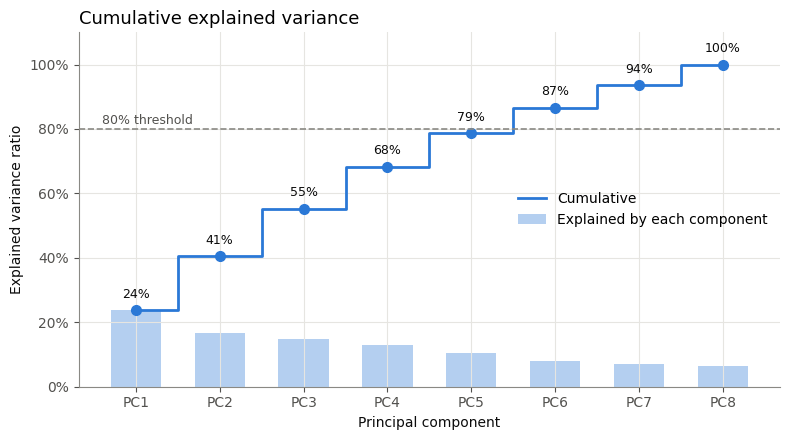

In [7]:
cumulative = np.cumsum(pca_full.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x, pca_full.explained_variance_ratio_, width=0.6, color=DATA_COLOR, alpha=0.35,
       label="Explained by each component")
ax.step(x, cumulative, where="mid", linewidth=2, color=DATA_COLOR, label="Cumulative")
ax.plot(x, cumulative, "o", markersize=7, color=DATA_COLOR)
ax.axhline(0.8, linestyle="--", linewidth=1.2, color=REF_COLOR)
ax.text(0.6, 0.815, "80% threshold", fontsize=9, color="#52514e")
for xi, c in zip(x, cumulative):
    ax.annotate(f"{c:.0%}", (xi, c), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=9, color="#0b0b0b")
ax.set_xticks(x, pc_names)
ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_title("Cumulative explained variance", loc="left", fontsize=13)
ax.legend(frameon=False, loc="center right")
plt.tight_layout()
plt.savefig(FIGURES / "p3_cumulative_variance.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.4 Selecting the number of components

The Week 11 lecture gives two rules of thumb. We also look at the scree plot.

In [8]:
r_80 = int(np.argmax(cumulative >= 0.8) + 1)
r_above_avg = int((pca_full.explained_variance_ > avg_eigenvalue).sum())

rules = pd.DataFrame({
    "rule": ["Rule 1: cumulative explained variance >= 80%",
             "Rule 2: keep PCs with above-average variance (eigenvalue > 1)"],
    "components": [r_80, r_above_avg],
    "variance kept": [cumulative[r_80 - 1], cumulative[r_above_avg - 1]],
})
rules.style.format({"variance kept": "{:.1%}"})

,rule,components,variance kept
0,Rule 1: cumulative explained variance >= 80%,6,86.6%
1,Rule 2: keep PCs with above-average variance (eigenvalue > 1),4,68.2%


**Decision: we retain 4 components (68.2% of the variance).**

- **Rule 2 (above-average variance) gives 4.** PC1 to PC4 each have an eigenvalue above 1, meaning each one explains more variance
  than a single original variable. PC5 to PC8 each explain less than one original variable (0.84 or lower), so keeping them would not
  summarize the data any better than the variables themselves.
- **Rule 1 (80%) gives 6.** Keeping 6 of 8 components would barely reduce the number of dimensions, which defeats the purpose of PCA
  before clustering (the curse of dimensionality).
- **Scree plot:** the biggest drop is between PC1 and PC2. After that the curve declines gradually and flattens after PC6,
  so there is no single clear elbow. The scree plot does not contradict keeping 4.

**Trade-off:** 4 components keep 68.2% of the variance and lose 31.8%. Our variables are only weakly correlated
(the strongest pair is r = -0.46), so the variance is spread across many directions and no small set of components can reach 80%.
In Project 3 we will also cluster with 6 components to check that the clusters do not change much.

In [9]:
N_RETAIN = r_above_avg
print("Components retained:", N_RETAIN)
print(f"Variance explained: {cumulative[N_RETAIN - 1]:.1%}")

Components retained: 4
Variance explained: 68.2%


### 2.5 Fit the final PCA and save the scores

In [30]:
pca = PCA(n_components=N_RETAIN, random_state=RANDOM_STATE)
scores = pd.DataFrame(pca.fit_transform(X_std), index=X_std.index,
                      columns=[f"PC{i}" for i in range(1, N_RETAIN + 1)])

# Loadings (eigenvectors) for the component interpretation section
loadings = pd.DataFrame(pca.components_.T, index=PCA_VARS, columns=scores.columns)

scores.reset_index().to_csv(PROCESSED / "dong_pca_scores.csv", index=False)
loadings.to_csv(PROCESSED / "pca_loadings.csv")
variance_table.to_csv(PROCESSED / "pca_explained_variance.csv")

print("Saved:", PROCESSED / "dong_pca_scores.csv", scores.shape)
print("Saved:", PROCESSED / "pca_loadings.csv", loadings.shape)
scores.head()

Saved: ../data/processed/dong_pca_scores.csv (365, 4)
Saved: ../data/processed/pca_loadings.csv (8, 4)


,PC1,PC2,PC3,PC4
Administrative_Dong_Code,,,,
11740700,0.676648,1.654410,-0.315373,-1.338464
11740690,1.070205,1.011259,0.953581,2.181605
11740685,-0.113494,-0.027448,-0.808275,0.987039
11740660,0.844171,1.990946,0.623331,-0.961363
11740650,-1.081947,-0.057226,0.542047,-0.110264


## 3. Component interpretation

*(In progress: loading table and heatmap, strongest variables per component, what each component represents.)*

## 4. Visualization and discussion

*(In progress: biplot of PC1 and PC2, visible patterns, link to research question and audience.)*

### 3.1 Component-loading table and visualization

In [32]:
loadings

,PC1,PC2,PC3,PC4
bakery_txn_share,0.201747,0.601218,0.163547,0.072796
gym_txn_share,0.508634,0.184587,-0.182876,-0.303247
gym_morning_share,0.467790,-0.380911,0.016209,0.301735
gym_evening_share,-0.453874,0.389308,0.125910,-0.205056
bakery_young_share,-0.092997,-0.401781,0.677091,0.005480
gym_female_share,0.077181,0.257516,-0.100791,0.788290
bakery_store_share,0.226744,0.279907,0.671821,0.077938
gym_density,0.457976,0.041477,0.061142,-0.377020


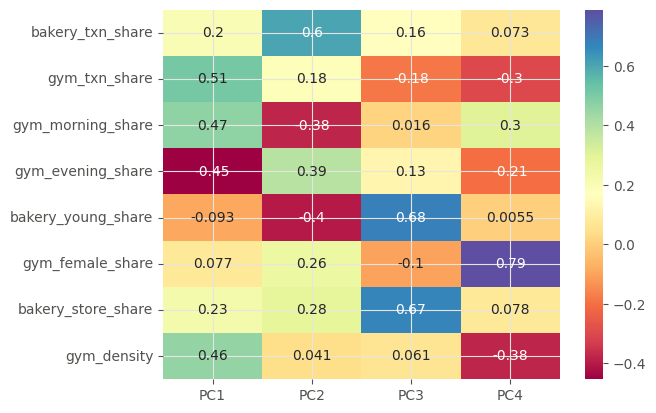

In [33]:
ax = sns.heatmap(loadings, annot=True, cmap='Spectral')
plt.savefig(FIGURES / "p3_loadings_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
# can browse characteristics of each principal component

### 3.2 Strongest variables that contribute to the retained components

In [39]:
# Rule of thumb from the Week 11 lecture : |loading| >= 0.3 
THRESHOLD = 0.3
strong = {}

for pc in loadings.columns:
    col = loadings[pc]
    strong[pc] = col[col.abs() >= THRESHOLD].round(3).to_dict()

strong

{'PC1': {'gym_txn_share': 0.509,
  'gym_morning_share': 0.468,
  'gym_evening_share': -0.454,
  'gym_density': 0.458},
 'PC2': {'bakery_txn_share': 0.601,
  'gym_morning_share': -0.381,
  'gym_evening_share': 0.389,
  'bakery_young_share': -0.402},
 'PC3': {'bakery_young_share': 0.677, 'bakery_store_share': 0.672},
 'PC4': {'gym_txn_share': -0.303,
  'gym_morning_share': 0.302,
  'gym_female_share': 0.788,
  'gym_density': -0.377}}

For PC1, gym_txn_share, gym_morning_share, gym_evening_share, gym_density,  
for PC2, bakery_txn_share, gym_evening_share, gym_evening_share, bakery_young_share,  
for PC3, bakery_young_share, bakery_store_share,  
for PC4, gym_txn_share, gym_morning_share, gym_female_share, gym_density,  
are the variables that contribute most strongly to the retained components.

### What the retained components represent

Using the lecture's rule of thumb(|loading| > 0.3):

- **PC1 (23.7%): Gym intensity and morning exercise.** High scores mean a larger share of spending at gyms, more licensed gyms per 1,000 stores, and gym visits concentrated in the morning rather than the evening. All four strong variables are gym variables, so PC1 is a "gym activity" axis.
- **PC2 (16.8%): Bakery spending share and an older bakery customer vase.** High scores mean bakeries take a larger share of all transactions, but bakery customers are less often in their 20s and 30s, and gym visits concentrated in the evening rather than the morning.
- **PC3 (14.7%): Young bakery districts.** High scores mean bakeries make up a larger share of all stores and their customers are mostly in their 20s and 30s. This axis describes bakery supply and young customers, not overall bakery spedning(as PC2).
- **PC4 (13.0%): Female share of gym customers.** Dominated by gym_female_share (0.79). Gym density and gym transaction share load negatively, and gym morning share sits at the threshold (0.30), so these are treated as borderline.

Gym variables(PC1) and bakery supply variables(PC3) load on different components. This suggests that how much a 행정동 "bulks"(bakery) and how much it "cuts"(gym) vary largely independently, rather than being two ends of one dimention.

The sign of each component is arbitrary, so "high" and "low" only describe relative positions on each axis. These labels are interpretations of the loadings, not confirmed groups of 행정동.

In [41]:
# Check which 행정동 have the highest PC1 scores
scores.join(features["Administrative_Dong_Name"]).sort_values(by=["PC1"], 
                                                              ascending=False).head(10)

,PC1,PC2,PC3,PC4,Administrative_Dong_Name
Administrative_Dong_Code,,,,,
11110560,4.734090,-0.259689,-1.320600,1.294605,Pyeongchang-dong
11170685,4.051221,-2.777926,0.669021,0.687265,Hannam-dong
11650581,3.964328,1.220038,-0.033097,-1.109103,Banpo 4-dong
11680590,3.452011,-1.811146,-1.142497,-1.316630,Samseong 2-dong
11320511,2.970344,1.860911,1.777741,-0.032557,Chang 1-dong
11590670,2.867789,-3.443871,1.552699,2.356710,Sindaebang 1-dong
11305608,2.686963,-1.080316,-0.247738,-0.503271,Beon 3-dong
11680655,2.525929,0.575135,-0.451524,-0.494273,Dogok 1-dong
11710650,2.415559,-0.149181,-0.597714,-0.734673,Jamsilbon-dong


## 4. Visualization and discussion

### 4.1 Create a biplot for PC1 and PC2 & describe visible patterns

In [42]:
# biplot: https://sukhbinder.wordpress.com/2015/08/05/biplot-with-python/
def biplot(score, coeff, pcax, pcay, labels=None):
  pca1 = pcax - 1
  pca2 = pcay - 1
    
  xs = score[:,pca1]
  ys = score[:,pca2]
    
  scalex = 1.0/(xs.max()- xs.min())
  scaley = 1.0/(ys.max()- ys.min())
    
  plt.figure(figsize=(8, 6))  
  plt.scatter(xs*scalex, ys*scaley, alpha = 0.5)

  n = coeff.shape[0]
  for i in range(n):
    plt.arrow(0, 0, coeff[i,pca1], coeff[i,pca2],color='r',alpha=0.5)
    if labels is None:
      plt.text(coeff[i,pca1]* 1.15, coeff[i,pca2] * 1.15, "Var"+str(i+1), color='g', ha='center', va='center')
    else:
      plt.text(coeff[i,pca1]* 1.15, coeff[i,pca2] * 1.15, labels[i], color='g', ha='center', va='center')
  plt.xlim(-1,1)
  plt.ylim(-1,1)
    
  plt.xlabel(f"PC{pcax} ({pca.explained_variance_ratio_[pca1]*100:.2f} %)")
  plt.ylabel(f"PC{pcay} ({pca.explained_variance_ratio_[pca2]*100:.2f} %)")
  plt.grid()

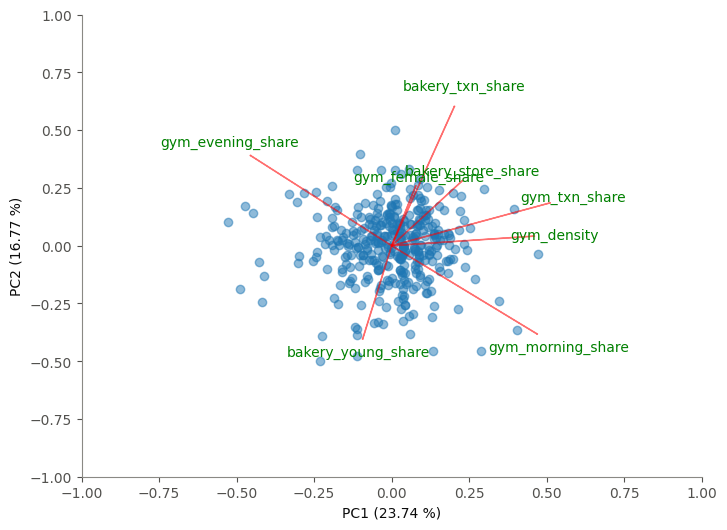

In [52]:
scores = pca.transform(X_std)
biplot(scores, pca.components_.T, 1, 2, labels=PCA_VARS)
plt.savefig(FIGURES / "p3_biplot.png", dpi=150, bbox_inches="tight")

### Biplot of PC1 and PC2

- **No separate groups.** The 행정동 form one roughly round cloud around the origin. This matches the weak correlations between the input variables. PCA shows directions of variation, not clusters, so any grouping will be tested with clustering in Project 3.
- **PC1 reflects gym activity.** gym_txn_share and gym_density point in almost the same direction, so 행정동 where gyms take a larger share of spending also tend to have more licensed gyms.
- **Morning vs. eveing exercise.** gym_morning_share and gym evening_share point in opposite directions, the strongest negative relationship in the date(r=-0.46). 행정동 lean toward either morning or an evening pattern.
- **Bakery spending vs. young bakery customers along PC2.** bakery_txn_share points up and bakery_young_share points down: where bakeries take a larger share of spending, their customers are less often in their 20s and 30s.
- **Short arrows.** bakery_store_share and gym_female_share are poorly represented in this plane. They load mainly on PC3, and PC4, which is one reason four components are retained rather than two.
- **Bakery and gym arrows are not opposite.** If "bulking" and "cutting" were two ends of one dimension, bakery and gym arrows would point in opposite directions. However, they point att an angle, so bakery and gym behavior are independent.
- **A few 행정동 on the far left** (PC1 = -0.4 to -0.5) combine low gym presence with evening-heavy gym use. These may include the 행정동 with very few gym transactions noted in preprocessing.

### 4.2 Relating the findings to the research question and audience

**Research question.** Can Seoul's 행정동 be grouped based on fitness and bakery related commercial activity, and what characteristics distinguish these groups?

**What PCA tells us so far.** PCA does not identify groups, and the PC1-PC2 biplot shows one continuous cloud rather than clearly separated sets of 행정동. However, PCA shows which dimensions any future groups are likely to differ on:

- PC1: how much fitness activity a 행정동 has, and whether gym use is morning- or evening-oriented
- PC2: how large a share of spending goes to bakeries, and how old the bakery customers are
- PC3: whether a 행정동 is a young bakery district (many bakeries, customers in their 20s and 30s)
- PC4: the share of female gym customers

Fitness variables load mainly on PC1, while bakery variables load mainly on PC2 and PC3.
Because these are separate dimensions, a 행정동 can have a same result on both, not having a clear black and white result. so rather than two simple types("bakery areas" vs. "fitness areas"), clustering in Project 3 may reveal groups that combine different levels of fitness and bakery activity.

**Relevance to each audience.**
- **Urban planners.** 행정동 with low PC1 scores have little fitness-related comercial activity. These are candidates for the further assessment of park accessbility and walkability described in our potential use, especially where they fall in 자치구 with relatively high obesity rates.
- **Public health policymakers.** Because bakery and fitness activity vary largely independently, a single indicator cannot describe a region's health environment. The food environment(PC2, PC3) and the physical activity environment(PC1) should be assessed separately when comparing regions.
- **Public health program planners.** PC1 separates morning-oriented from evening-oriented gym areas. This could help decide whether community exercise programs in a 행정동 should be offered in the early morning or after work.

**Next steps and limits.** In Project 3, we will cluster 행정동 on the four retained components, then compare the clusters by worker and resident population. To relate them to obesity, cluster results will be summarized at the 자치구 level, since obesity rates are only available at that scale. For example, whether evening-oriented gym areas are office-heavy areas will be tested with the worker share, which was held out of PCA. 